# 2026 Microbial species frequencies and community phenotype
# Random-forest machine-learning

In [2]:
cwd = "/scratch/project_2000746/anthosun/2026FQPH/"

In [60]:
import numpy as np
import scipy as sp
import pandas as pd
from numpy.random import default_rng

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier

In [59]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# Simple functions

In [5]:
def turn_labels_to_str(frame):
    df = frame.copy()
    if isinstance(df.index, pd.MultiIndex):
        index = pd.MultiIndex.from_frame(df.index.to_frame().astype(str), names = df.index.names)
    else:
        index = pd.Index(df.index, dtype=str, name = df.index.name)
        
    if isinstance(df.columns, pd.MultiIndex):
        columns = pd.MultiIndex.from_frame(df.columns.to_frame().astype(str), names = df.columns.names)
    else:
        columns = pd.Index(df.columns, dtype=str, name = df.columns.name)

    df.index = index
    df.columns = columns
    
    return df

In [6]:
# train/test mask with 1/4 for testing

def draw_train_test_masks(X):
    
    whole = np.arange(X.shape[0])
    whole = whole.reshape((len(whole) // 8, 8,))
    mask = []
    for i in range(len(whole)):
        for j in rng.choice(8, size = 2, replace=False):
            mask.append(whole[i,j])
    mask = np.array(mask)
    whole = whole.flatten()
    
    test_mask = np.array([x in mask for x in whole])
    train_mask = np.array([not x in mask for x in whole])
    
    return train_mask, test_mask

## Loading data

In [7]:
amps = pd.read_csv("{}/data/[AMP]s.csv".format(cwd))
F = pd.read_csv("{}/data/Freqs.csv".format(cwd), header=[0,], index_col=[0,1,2,3,])
summary = pd.read_csv("{}/data/Phnt_strs_normalised_summary.csv".format(cwd), header=[0,1], index_col=[0,1,2,3,])
joint = pd.read_csv("{}/data/Join_freq_phnt.csv".format(cwd), header=[0,1], index_col=[0,1,2,3,])

In [8]:
R = pd.read_csv("{}/data/RPCA.csv".format(cwd), header=[0,1], index_col=[0,1,2,3,],)

In [9]:
F_dayss = F.index.get_level_values(level = "days").unique()
R_dayss = R.index.get_level_values(level = "days").unique()

In [10]:
joint_dayss = joint.index.get_level_values("days").unique()

for d, days in enumerate(joint_dayss):
    
    phnt_days = R_dayss[np.argmin(np.abs(np.array([int(x) for x in R_dayss]) - days))]
    phnt_clid = R.xs(phnt_days, level = "days", axis =0).copy()
    phnt_clid = pd.concat({days: phnt_clid}, names=["days"])#.unstack(1)
    phnt_clid.columns.names = ["feat", "strs",]
    
    freq_days = F_dayss[np.argmin(np.abs(np.array([int(x) for x in F_dayss]) - days))]
    freq_clid = F.xs(freq_days, level = "days", axis =0).copy()
    freq_clid = pd.concat({days: freq_clid}, names=["days"])
    freq_clid = pd.concat({"freq": freq_clid}, names=["strs", "feat",], axis = 1).swaplevel(axis = 1)
    
    FR = pd.concat([phnt_clid, freq_clid,], axis=1, ) if d == 0 else pd.concat([FR, pd.concat([phnt_clid, freq_clid,], axis = 1, ),], axis=0)

In [11]:
FR.to_csv("/scratch/project_2000746/anthosun/FR.csv")

In [12]:
FRF = FR.xs("freq", level="strs", axis=1)
FRR = FR.drop("freq", level="strs", axis=1)

In [12]:
#N = pd.read_csv("{}/data/Phnt_strs.csv".format(cwd), header=[0,1,2,3,4,], index_col=[0,], )
#R = pd.read_csv("{}/data/Phnt_strs_rhos.csv".format(cwd), header=[0,1,2,3,4,], index_col=[0,], )

# Predictions of [AMP]

In [13]:
rng = default_rng()

n_estimators = 100
max_depth = None # max_depth for random-forest regressor trees

f = RandomForestRegressor(n_estimators = n_estimators, max_depth = max_depth)

## From phenotypes to current [AMP]

In [70]:
RRR = pd.read_csv("{}/data/RPCA.csv".format(cwd), header=[0,1], index_col=[0,1,2,3,],)
RRR.drop("Rclid", level = "feat", axis=1, inplace = True)
dfindex = RRR.index.to_frame()
dfindex[["[AMP]", "[AMP]max"]] = dfindex[["days", "ablv"]].apply(lambda x: amps.set_index(["days", "ablv"]).loc[tuple(x)], axis=1)
RRR.index = pd.MultiIndex.from_frame(dfindex)

In [ ]:
df_target = RRR.index.to_frame()["[AMP]"]

nreps = 100

strss = RRR.columns.get_level_values("strs").unique()
nstrs = len(strss)
res = np.zeros((2, nstrs + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):

    df = RRR.copy()
    train_mask, test_mask = draw_train_test_masks(df_target)
    
    # predict from all stressors together
        
    m = f.fit(df.iloc[train_mask], df_target.iloc[train_mask], )
    trn = m.score(df.iloc[train_mask], df_target.iloc[train_mask], )
    importances = f.feature_importances_ if r == 0 else importances + f.feature_importances_
    tst = m.score(df.iloc[test_mask], df_target.iloc[test_mask], )
    res[:,0,r] = [trn, tst]
    
    # predict from each stressor alone

    for s, strs in enumerate(strss):
        
        df = RRR.xs(strs, level="strs", axis=1)
        
        m = f.fit(df.iloc[train_mask], df_target.iloc[train_mask], )
        trn = m.score(df.iloc[train_mask], df_target.iloc[train_mask], )
        tst = m.score(df.iloc[test_mask], df_target.iloc[test_mask], )
        res[:,s+1,r] = [trn, tst]

In [ ]:
importances = pd.DataFrame(importances / nreps, index=RRR.columns).unstack().xs(0, axis=1)

importances.loc["sum", :] = importances.sum(axis=0)
importances.loc[:, "sum"] = importances.sum(axis=1)

importances.to_csv("{}/data/RF_R2[AMP]_importances.csv".format(cwd), sep=",", )

In [90]:
R2AMP = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strss), index = ["trn_avg", "trn_mdn"], ).T
R2AMP = pd.concat([R2AMP, pd.DataFrame(res[1], index = ["all"] + list(strss), )], axis = 1)
R2AMP.to_csv("{}/data/RF_R2[AMP].csv".format(cwd), sep=",", )

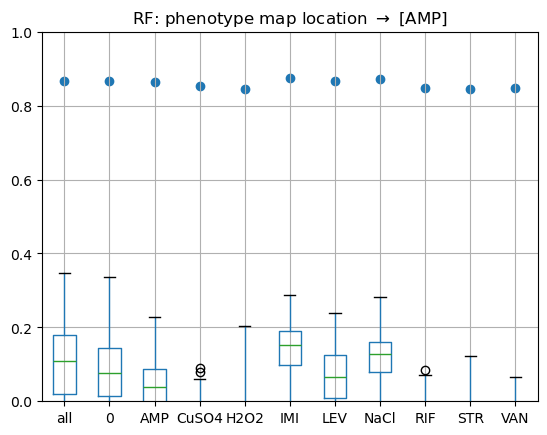

In [92]:
R2AMP = pd.read_csv("{}/data/RF_R2[AMP].csv".format(cwd), index_col=[0])

ax = R2AMP.drop(["trn_avg", "trn_mdn"], axis = 1).T.boxplot(return_type="axes")
ax.scatter(range(1, len(R2AMP["trn_avg"]) + 1), R2AMP["trn_avg"], )
ax.set(ylim = (0,1), title = r"RF: phenotype map location $\to$ [AMP]")

### SAVING
name = "{}/plot/rfml_R2[AMP].png".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

## From phenotypes to highest [AMP] experienced

In [99]:
RRR = pd.read_csv("{}/data/RPCA.csv".format(cwd), header=[0,1], index_col=[0,1,2,3,],)
RRR.drop("Rclid", level = "feat", axis=1, inplace = True)
dfindex = RRR.index.to_frame()
dfindex[["[AMP]", "[AMP]max"]] = dfindex[["days", "ablv"]].apply(lambda x: amps.set_index(["days", "ablv"]).loc[tuple(x)], axis=1)
RRR.index = pd.MultiIndex.from_frame(dfindex)

In [100]:
df_target = RRR.index.to_frame()["[AMP]max"]

nreps = 100

strss = RRR.columns.get_level_values("strs").unique()
nstrs = len(strss)
res = np.zeros((2, nstrs + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):

    df = RRR.copy()
    train_mask, test_mask = draw_train_test_masks(df_target)
    
    # predict from all stressors together
    
        
    m = f.fit(df.iloc[train_mask], df_target.iloc[train_mask], )
    trn = m.score(df.iloc[train_mask], df_target.iloc[train_mask], )
    importances = f.feature_importances_ if r == 0 else importances + f.feature_importances_
    tst = m.score(df.iloc[test_mask], df_target.iloc[test_mask], )
    res[:,0,r] = [trn, tst]
    
    # predict from each stressor alone

    for s, strs in enumerate(strss):
        
        df = RRR.xs(strs, level="strs", axis=1)
        
        m = f.fit(df.iloc[train_mask], df_target.iloc[train_mask], )
        trn = m.score(df.iloc[train_mask], df_target.iloc[train_mask], )
        tst = m.score(df.iloc[test_mask], df_target.iloc[test_mask], )
        res[:,s+1,r] = [trn, tst]

In [101]:
importances = pd.DataFrame(importances / nreps, index=RRR.columns).unstack().xs(0, axis=1)

importances.loc["sum", :] = importances.sum(axis=0)
importances.loc[:, "sum"] = importances.sum(axis=1)

importances.to_csv("{}/data/RF_R2[AMP]max_importances.csv".format(cwd), sep=",", )

In [102]:
R2AMP = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strss), index = ["trn_avg", "trn_mdn"], ).T
R2AMP = pd.concat([R2AMP, pd.DataFrame(res[1], index = ["all"] + list(strss), )], axis = 1)
R2AMP.to_csv("{}/data/RF_R2[AMP]max.csv".format(cwd), sep=",", )

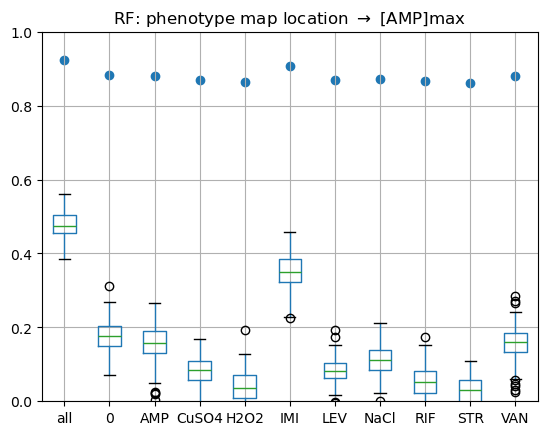

In [103]:
R2AMP = pd.read_csv("{}/data/RF_R2[AMP]max.csv".format(cwd), index_col=[0])

ax = R2AMP.drop(["trn_avg", "trn_mdn"], axis = 1).T.boxplot(return_type="axes")
ax.scatter(range(1, len(R2AMP["trn_avg"]) + 1), R2AMP["trn_avg"], )
ax.set(ylim = (0,1), title = r"RF: phenotype map location $\to$ [AMP]max")

### SAVING
name = "{}/plot/rfml_R2[AMP]max.png".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

## Plotting both

In [120]:
R2AMP = pd.read_csv("{}/data/RF_R2[AMP].csv".format(cwd), index_col=[0])
R2AMPmax = pd.read_csv("{}/data/RF_R2[AMP]max.csv".format(cwd), index_col=[0])

df = pd.concat({"[AMP]": R2AMP, "[AMP]max": R2AMPmax, }, names=["target", "stressor"])

In [136]:
data =  df.drop(["trn_avg", "trn_mdn"], axis = 1).stack().reset_index()
data.columns = ["target", "stressor", "id", "score"]

In [173]:
gap = 1 / 5

coord = np.tile(np.arange(0, len(df.index.get_level_values("stressor").unique() ), dtype=float)[:,np.newaxis], (1,2),)
coord[:,0] -= gap
coord[:,1] += gap

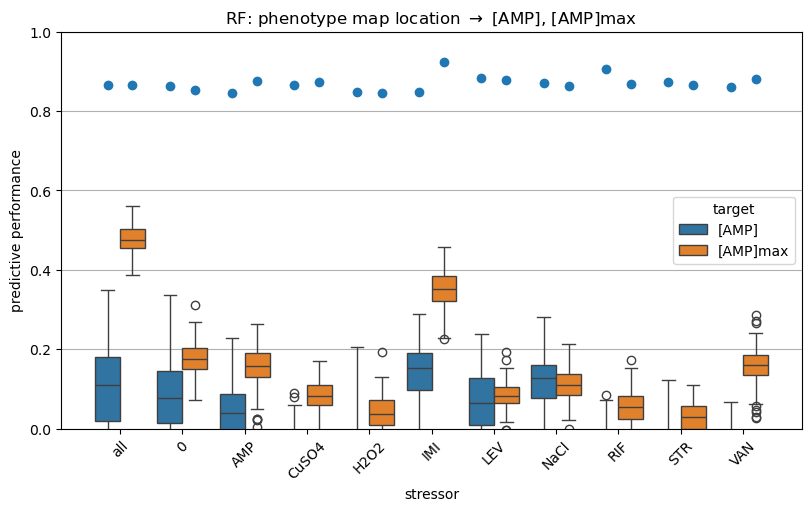

In [175]:
fig = plt.figure(figsize=(8, 5), constrained_layout=True)
gs = fig.add_gridspec(1, 2)

ax = fig.add_subplot(gs[:,:])

ax = sns.boxplot(data = data.reset_index(), x = "stressor", y = "score", hue = "target", ax = ax, )
ax.scatter(coord.flatten(), df["trn_avg"].values.flatten(), )

ax.set(ylim = (0,1),
       xlabel = "stressor", ylabel = "predictive performance",
       title = r"RF: phenotype map location $\to$ [AMP], [AMP]max", )
ax.tick_params("x", rotation=45)
ax.grid(visible=True, axis = "y")

### SAVING
name = "{}/plot/rfml_R2[AMP]_R2[AMP]max.png".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

# Predictions between frequencies and phenotypes

In [76]:
rng = default_rng()

In [77]:
n_estimators = 100
max_depth = None # max_depth for random-forest regressor trees

f = RandomForestRegressor(n_estimators = n_estimators, max_depth = max_depth)

## From frequencies to phenotypes

In [ ]:
nreps = 100

strss = FRR.columns.get_level_values("strs").unique()
nstrs = len(strss)

res = np.zeros((2, nstrs + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):

    train_mask, test_mask = draw_train_test_masks(FR)
    
    # predict all stressors together
    
    m = f.fit(FRF.iloc[train_mask], FRR.iloc[train_mask], )
    trn = m.score(FRF.iloc[train_mask], FRR.iloc[train_mask], )
    tst = m.score(FRF.iloc[test_mask], FRR.iloc[test_mask], )
    res[:,0,r] = [trn, tst]
    
    # predict each stressor alone
    
    for s, strs in enumerate(strss):
        
        m = f.fit(FRF.iloc[train_mask], FRR.xs(strs, level="strs", axis=1).iloc[train_mask], )
        trn = m.score(FRF.iloc[train_mask], FRR.xs(strs, level="strs", axis=1).iloc[train_mask], )
        tst = m.score(FRF.iloc[test_mask], FRR.xs(strs, level="strs", axis=1).iloc[test_mask], )
        res[:,s+1,r] = [trn, tst]

In [91]:
F2R = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strss), index = ["trn_avg", "trn_mdn"], ).T
F2R = pd.concat([F2R, pd.DataFrame(res[1], index = ["all"] + list(strss), )], axis = 1)
F2R.to_csv("{}/data/RF_F2R.csv".format(cwd), sep=",", )

### From frequencies + IC50s to phenotypes

In [43]:
IC50s = pd.read_csv("{}/data/log10_IC50s.csv".format(cwd), index_col=[0])
IC50s = turn_labels_to_str(IC50s)

In [33]:
FRF = FR.xs("freq", level="strs", axis=1)
FRR = FR.drop("freq", level="strs", axis=1)

ANC_mask = FRF.index.get_level_values("hist") == "ANC"
EVO_mask = FRF.index.get_level_values("hist") == "EVO"

FRF.loc[ANC_mask,:] *= IC50s.loc[:,"ANC"]
FRF.loc[EVO_mask,:] *= IC50s.loc[:,"EVO"]

In [37]:
nreps = 10

strss = FRR.columns.get_level_values("strs").unique()
nstrs = len(strss)

res = np.zeros((2, nstrs + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):

    train_mask, test_mask = draw_train_test_masks(FR)
    
    # predict all stressors together
    
    m = f.fit(FRF.iloc[train_mask], FRR.iloc[train_mask], )
    trn = m.score(FRF.iloc[train_mask], FRR.iloc[train_mask], )
    tst = m.score(FRF.iloc[test_mask], FRR.iloc[test_mask], )
    res[:,0,r] = [trn, tst]
    
    # predict each stressor alone
    
    for s, strs in enumerate(strss):
        
        m = f.fit(FRF.iloc[train_mask], FRR.xs(strs, level="strs", axis=1).iloc[train_mask], )
        trn = m.score(FRF.iloc[train_mask], FRR.xs(strs, level="strs", axis=1).iloc[train_mask], )
        tst = m.score(FRF.iloc[test_mask], FRR.xs(strs, level="strs", axis=1).iloc[test_mask], )
        res[:,s+1,r] = [trn, tst]

In [38]:
F2R = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strss), index = ["trn_avg", "trn_mdn"], ).T
F2R = pd.concat([F2R, pd.DataFrame(res[1], index = ["all"] + list(strss), )], axis = 1)
F2R.to_csv("{}/data/RF_F2R_IC50.csv".format(cwd), sep=",", )

In [54]:
# ordering of stressors based on the variance of the per-capita growth rates that they induce
R_index = ["all"] + pd.read_csv("{}/data/Phnt_strs_rhos.csv".format(cwd), header=[0,1,2,3,4,], index_col=[0,], ).unstack().groupby("strs").var().sort_values(ascending=False).index.to_list()

In [55]:
F2R = pd.read_csv("{}/data/RF_F2R_IC50.csv".format(cwd), index_col=[0]).loc[R_index]

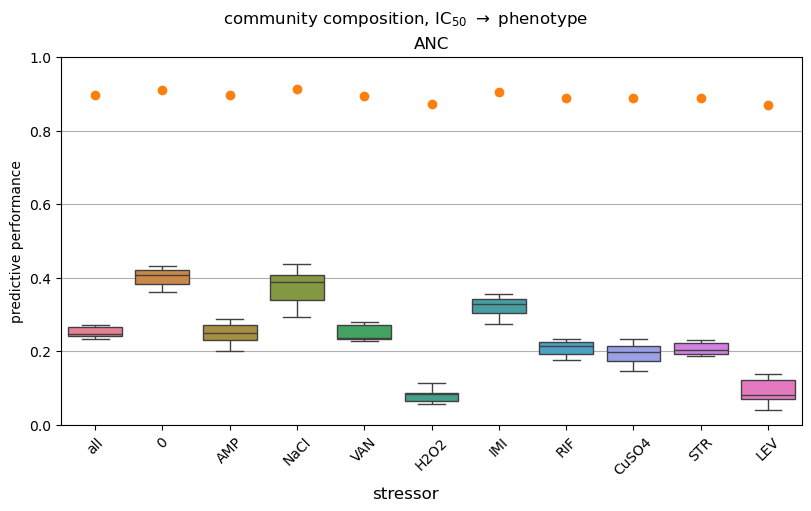

In [56]:
fig = plt.figure(figsize=(8, 5), constrained_layout=True)
fig.suptitle(r"community composition, IC$_{50}$ $\to$ phenotype",)
fig.supxlabel("stressor",)

ax = fig.add_subplot()

ax = sns.boxplot(data = F2R.drop(["trn_avg", "trn_mdn"], axis = 1).T, ax = ax, showfliers=False, )
ax.scatter(range(len(F2R["trn_avg"])), F2R["trn_avg"], )
ax.set(xlim = (-0.5,10.5), ylim = (0,1), ylabel = "predictive performance",
       title = "ANC" )
ax.tick_params("x", rotation=45)
ax.grid(visible=True, axis = "y")

### SAVING
name = "{}/plot/rfml_F2R_IC50.png".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

## From frequencies to phenotypes in ANC and in EVO

In [101]:
FRF_ANC = FRF.xs("ANC", level = "hist")
FRR_ANC = FRR.xs("ANC", level = "hist")
FRF_EVO = FRF.xs("EVO", level = "hist")
FRR_EVO = FRR.xs("EVO", level = "hist")

### In ANC

In [102]:
nreps = 100

strss = FRR_ANC.columns.get_level_values("strs").unique()
nstrs = len(strss)

res = np.zeros((2, nstrs + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):

    train_mask, test_mask = draw_train_test_masks(FRF_ANC)
    
    # predict all stressors together
    
    m = f.fit(FRF_ANC.iloc[train_mask], FRR_ANC.iloc[train_mask], )
    trn = m.score(FRF_ANC.iloc[train_mask], FRR_ANC.iloc[train_mask], )
    tst = m.score(FRF_ANC.iloc[test_mask], FRR_ANC.iloc[test_mask], )
    res[:,0,r] = [trn, tst]
    
    # predict each stressor alone
    
    for s, strs in enumerate(strss):
        
        m = f.fit(FRF_ANC.iloc[train_mask], FRR_ANC.xs(strs, level="strs", axis=1).iloc[train_mask], )
        trn = m.score(FRF_ANC.iloc[train_mask], FRR_ANC.xs(strs, level="strs", axis=1).iloc[train_mask], )
        tst = m.score(FRF_ANC.iloc[test_mask], FRR_ANC.xs(strs, level="strs", axis=1).iloc[test_mask], )
        res[:,s+1,r] = [trn, tst]

In [103]:
F2R = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strss), index = ["trn_avg", "trn_mdn"], ).T
F2R = pd.concat([F2R, pd.DataFrame(res[1], index = ["all"] + list(strss), )], axis = 1)
F2R.to_csv("{}/data/RF_F2R_ANC.csv".format(cwd), sep=",", )

### In EVO

In [105]:
F2R = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strss), index = ["trn_avg", "trn_mdn"], ).T
F2R = pd.concat([F2R, pd.DataFrame(res[1], index = ["all"] + list(strss), )], axis = 1)
F2R.to_csv("{}/data/RF_F2R_EVO.csv".format(cwd), sep=",", )

In [104]:
nreps = 100

strss = FRR_EVO.columns.get_level_values("strs").unique()
nstrs = len(strss)

res = np.zeros((2, nstrs + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):

    train_mask, test_mask = draw_train_test_masks(FRF_EVO)
    
    # predict all stressors together
    
    m = f.fit(FRF_EVO.iloc[train_mask], FRR_EVO.iloc[train_mask], )
    trn = m.score(FRF_EVO.iloc[train_mask], FRR_EVO.iloc[train_mask], )
    tst = m.score(FRF_EVO.iloc[test_mask], FRR_EVO.iloc[test_mask], )
    res[:,0,r] = [trn, tst]
    
    # predict each stressor alone
    
    for s, strs in enumerate(strss):
        
        m = f.fit(FRF_EVO.iloc[train_mask], FRR_EVO.xs(strs, level="strs", axis=1).iloc[train_mask], )
        trn = m.score(FRF_EVO.iloc[train_mask], FRR_EVO.xs(strs, level="strs", axis=1).iloc[train_mask], )
        tst = m.score(FRF_EVO.iloc[test_mask], FRR_EVO.xs(strs, level="strs", axis=1).iloc[test_mask], )
        res[:,s+1,r] = [trn, tst]

## From phenotypes to frequencies

In [19]:
nreps = 100

strns = FRF.columns.get_level_values("feat").unique()
nstns = len(strns)

res = np.zeros((2, nstns + 1, nreps)) # array for result-scores ([train, test], [all stressors then each stressor], repeats)

for r in range(nreps):

    train_mask, test_mask = draw_train_test_masks(FR)
    
    # predict all strains together
    
    m = f.fit(FRR.iloc[train_mask], FRF.iloc[train_mask], )
    trn = m.score(FRR.iloc[train_mask], FRF.iloc[train_mask], )
    tst = m.score(FRR.iloc[test_mask], FRF.iloc[test_mask], )
    res[:,0,r] = [trn, tst]
    
    # predict each strain alone
    
    for i, strn in enumerate(strns):
        
        m = f.fit(FRR.iloc[train_mask], FRF.loc[train_mask,strn], )
        trn = m.score(FRR.iloc[train_mask], FRF.loc[train_mask,strn], )
        tst = m.score(FRR.iloc[test_mask], FRF.loc[test_mask,strn], )
        res[:,i+1,r] = [trn, tst]

In [21]:
R2F = pd.DataFrame([np.mean(res[0], axis=-1), np.median(res[0], axis=-1), ], columns = ["all"] + list(strns), index = ["trn_avg", "trn_mdn"], ).T
R2F = pd.concat([R2F, pd.DataFrame(res[1], index = ["all"] + list(strns), )], axis = 1)
R2F.to_csv("{}/data/RF_R2F.csv".format(cwd), sep=",", )

# Plotting Fig. 6

In [22]:
# ordering of strains based on the variance of their frequencies
F_index = ["all"] + pd.read_csv("{}/data/Freqs.csv".format(cwd), header=[0,], index_col=[0,1,2,3,]).var(axis=0).sort_values(ascending=False).index.to_list()

# ordering of stressors based on the variance of the per-capita growth rates that they induce
R_index = ["all"] + pd.read_csv("{}/data/Phnt_strs_rhos.csv".format(cwd), header=[0,1,2,3,4,], index_col=[0,], ).unstack().groupby("strs").var().sort_values(ascending=False).index.to_list()

In [50]:
F2R = pd.read_csv("{}/data/RF_F2R.csv".format(cwd), index_col=[0]).loc[R_index]
R2F = pd.read_csv("{}/data/RF_R2F.csv".format(cwd), index_col=[0]).loc[F_index]
F2R_ANC = pd.read_csv("{}/data/RF_F2R_ANC.csv".format(cwd), index_col=[0]).loc[R_index]
F2R_EVO = pd.read_csv("{}/data/RF_F2R_EVO.csv".format(cwd), index_col=[0]).loc[R_index]

F2R_all = pd.concat({"ANC+EVO": F2R, "ANC": F2R_ANC, "EVO": F2R_EVO, }, names = ["hist", "strs"])

F2R_all.rename({"all": "all stressors"}, inplace = True)
R2F.rename({"all": "all sp."}, inplace = True)

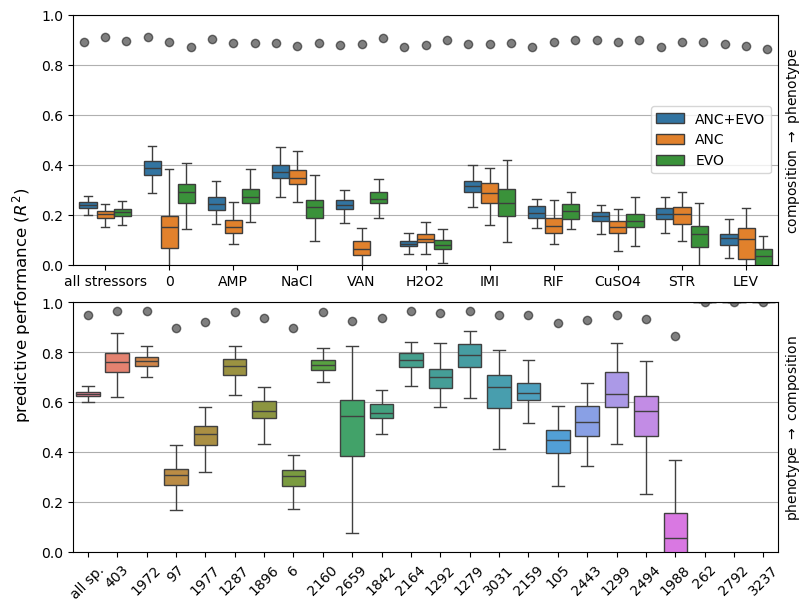

In [57]:
fig = plt.figure(figsize=(8, 6), constrained_layout=True)
fig.supylabel(r"predictive performance ($R^2$)",)
gs = fig.add_gridspec(2, 1)

# top: composition to phenotype

ax = fig.add_subplot(gs[0,0])

ax.scatter(np.arange(0, len(F2R_all["trn_avg"]) ) / 3 - 1/3, F2R_all["trn_avg"], c="k", alpha = 0.5)

sns.boxplot(data = F2R_all.drop(["trn_avg", "trn_mdn"], axis = 1).T.melt(),
            ax = ax, showfliers=False, x = "strs", y = "value", hue = "hist")
ax.set(ylim = (0,1), xlabel = "", ylabel = r"composition $\to$ phenotype")
#ax.tick_params("x", rotation=45)
ax.grid(visible=True, axis = "y")
ax.yaxis.set_label_position("right")

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels)

# bottom: phenotype to composition

ax = fig.add_subplot(gs[1,:], )

ax.scatter(range(len(R2F["trn_avg"])), R2F["trn_avg"], c="k", alpha = 0.5 )
sns.boxplot(data = R2F.drop(["trn_avg", "trn_mdn"], axis = 1).T, ax = ax, showfliers=False)
ax.set(xlim = (-0.5,23.5), ylim = (0,1), xlabel = "", ylabel = r"phenotype $\to$ composition",)
ax.tick_params("x", rotation=45)
ax.grid(visible=True, axis = "y")#xdata = np.arange(8) * 3)
ax.yaxis.set_label_position("right")

### SAVING
name = "{}/plot/RF.pdf".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()

# Fig. S5

## Computing

In [ ]:
from itertools import combinations

In [ ]:
strss = FRR.columns.get_level_values("strs").unique()
nstrs = len(strss)

strns = FRF.columns.get_level_values("feat").unique()
nstns = len(strns)

In [ ]:
res = np.zeros((2, 2**nstrs - 1)) # array for result-scores ([train, test], [all combinations of stressors], )
lbl = []

for nb in range(1, nstrs + 1):
    for comb in combinations(strss, nb):

        train_mask, test_mask = draw_train_test_masks(FR)
        
        # predict all strains together
        
        m = f.fit(FRR.loc[train_mask,(slice(None),comb)], FRF.iloc[train_mask], )
        trn = m.score(FRR.loc[train_mask,(slice(None),comb)], FRF.iloc[train_mask], )
        tst = m.score(FRR.loc[test_mask,(slice(None),comb)], FRF.iloc[test_mask], )
        res[:,len(lbl)] = [trn, tst]
        
        lbl.append(comb)
    

In [ ]:
RRR2F = pd.DataFrame(res, index = ["trn", "tst"],)
RRR2F.columns = pd.MultiIndex.from_arrays([[len(label) for label in lbl], lbl,], names = ["nb", "stressors"] )
RRR2F.T.to_csv("{}/data/RF_RRR2F.csv".format(cwd), sep=",", )

## Plotting

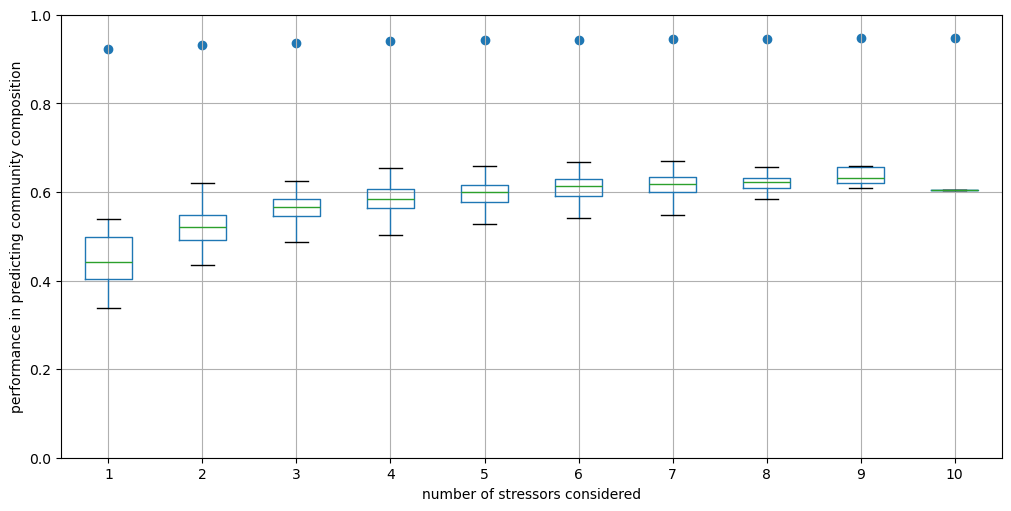

In [62]:
RRR2F = pd.read_csv("{}/data/RF_RRR2F.csv".format(cwd), index_col=[0,1])
nstrs = 10

fig = plt.figure(figsize=(10, 5), constrained_layout=True)
ax = fig.add_subplot()

RRR2F["tst"].unstack().T.boxplot(return_type="axes", ax = ax, showfliers=False)
ax.scatter(range(1, nstrs + 1), RRR2F["trn"].groupby("nb").mean(), )
ax.set(ylim = (0,1),
       xlabel = "number of stressors considered", ylabel = "performance in predicting community composition",
#       title = r"RF: phenotype map location $\to$ community composition",
      )

### SAVING
name = "{}/plot/rfml_RRR2F.png".format(cwd,)
plt.savefig(name, facecolor='w', edgecolor='w', transparent=False, bbox_inches="tight")
plt.show()